# Pre-arrest classification — audited training notebook

Research-only pipeline. **Not clinically validated**. Labels must be checked against documented event timestamps and a predefined prediction horizon.

The model-selection table uses grouped out-of-fold predictions. These same folds are used to choose a model, so the winning score is **not an unbiased final test estimate**. For final evaluation, select models and thresholds using training/validation patients only, then assess once on untouched test patients and an external database.

For local execution the CSV path is configured to `/mnt/data/train_ready.csv`; change it if needed.

In [4]:
!pip install -q xgboost lightgbm

In [5]:
# ============ CONFIG ============
DATA_PATH   = "/content/train_ready.csv"            # None = upload train_ready.csv when prompted. Or e.g. "/content/train_ready.csv"
TARGET_COL  = "label_prearrest"   # 1 = pre-arrest window, 0 = normal
GROUP_COL   = "patient_id"        # one patient has many windows -> never split a patient
SOURCE_COL  = "stratum"           # database name (vfdb / mitdb / sddb): evaluation only, NEVER a feature
ORDER_COL   = "orig_row"          # must increase with time inside a patient (windows are sequential)

# Base HRV features. Deliberately NOT included:
#   n_beats            -> depends on how the database was sampled/segmented (database fingerprint)
#   lf, hf, lf_hf      -> unreliable on ~1-minute windows (~110 beats)
#   mean_hr, sdsd, sd1 -> almost perfectly collinear with mean_rr / rmssd
#   n_ventricular, pvc_burden, max_consec_ventricular, non_n_fraction -> missing in VFDB (database fingerprint)
BASE_FEATS = ["mean_rr", "sdnn", "rmssd", "pnn50", "min_rr", "max_rr", "cv_rr", "sd2", "premature_fraction"]

FEATURE_SET   = "relative"    # "relative" | "absolute" | "both"   (the ablation cell compares all three)
BASELINE_MODE = "expanding"   # "expanding"   = baseline from the patient's PAST windows only (usable in real time)
                              # "patient_all" = baseline from ALL the patient's windows (not causal; diagnostic only)
MIN_HISTORY   = 5             # windows of history needed before a baseline exists (earlier windows get z = 0)
SHORT_WIN     = 10            # rolling window (in windows) for the z-mean / z-std trend features

SOURCES_TO_USE       = None   # None = all databases, or e.g. ["sddb", "vfdb"] to drop a database whose negatives are
                              # a different kind of patient (e.g. mitdb patients never arrest)
NORMALIZE_PER_SOURCE = False  # EXPERIMENT: z-score every feature inside each database. Removes database shift,
                              # but cannot be used on a patient from an unknown database -> saving is blocked if True

CV_FOLDS, CV_REPEATS, RANDOM_SEED = 5, 5, 42
# Set CV_REPEATS=1 for a quick diagnostic; restore 5 for a fuller comparison.
W_ROC, W_PR = 0.5, 0.5        # selection score = W_ROC*(2*ROC-1) + W_PR*(PR-AUC - base)/(1 - base); both are 0 at chance
RUN_ABLATION = True           # compare absolute / relative / both feature sets (adds a few minutes)

SMOOTH_K     = 5              # per-patient causal rolling median over the last K windows (1 = no smoothing)
WATCH_RATE   = 0.05           # WATCH   = top 5% highest-risk windows
WARNING_RATE = 0.01           # WARNING = top 1% highest-risk windows
# ================================

In [6]:
import os, sys, warnings, joblib
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
try:
    display
except NameError:
    display = print

if DATA_PATH is None:
    from google.colab import files
    print("Upload your dataset (CSV or Excel):")
    DATA_PATH = next(iter(files.upload()))
df = pd.read_excel(DATA_PATH) if DATA_PATH.endswith(("xlsx", "xls")) else pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH, df.shape)

missing = [c for c in [TARGET_COL, GROUP_COL, ORDER_COL] + BASE_FEATS if c not in df.columns]
assert not missing, f"Columns missing from the data: {missing}"

df = df[df[TARGET_COL].notna()].copy()
df[TARGET_COL] = df[TARGET_COL].astype(int)
if SOURCE_COL not in df.columns:
    df[SOURCE_COL] = "all"
if SOURCES_TO_USE:
    df = df[df[SOURCE_COL].isin(SOURCES_TO_USE)]
df = df.sort_values([GROUP_COL, ORDER_COL]).reset_index(drop=True)

y = df[TARGET_COL].copy()
groups = df[GROUP_COL].values
sources = df[SOURCE_COL].astype(str).values
base_rate = float(y.mean())

# ---------------- data diagnostics ----------------
rank = df.groupby(GROUP_COL).cumcount() / (df.groupby(GROUP_COL)[ORDER_COL].transform("size") - 1).clip(lower=1)
pat = df.groupby(GROUP_COL).agg(source=(SOURCE_COL, "first"), windows=(TARGET_COL, "size"), pos=(TARGET_COL, "sum"))
pat["pos_frac"] = pat["pos"] / pat["windows"]
pat["pos_position"] = rank[y == 1].groupby(df.loc[y == 1, GROUP_COL]).mean()   # 0 = start of recording, 1 = end

summary = pat.groupby("source").agg(patients=("windows", "size"), windows=("windows", "sum"), pos_windows=("pos", "sum"),
                                    patients_with_pos=("pos", lambda s: int((s > 0).sum())),
                                    all_positive_patients=("pos_frac", lambda s: int((s == 1).sum())))
summary["base_rate"] = (summary["pos_windows"] / summary["windows"]).round(3)
print(f"\nOverall: {len(df)} windows, {df[GROUP_COL].nunique()} patients, positive rate {base_rate:.3f}")
display(summary)

mixed = pat[(pat["pos"] > 0) & (pat["pos_frac"] < 1)]
if len(mixed):
    print(f"\n{len(mixed)} patients have BOTH normal and pre-arrest windows (the clean within-patient comparison).")
    print(f"Median position of their positive windows: {mixed['pos_position'].median():.2f}  (1.0 = end of recording)")
    if mixed["pos_position"].median() < 0.4:
        print("WARNING: positives sit near the START of the recordings. A baseline built from past windows will be empty "
              "for them. Check ORDER_COL really is time order, or try BASELINE_MODE='patient_all' as a diagnostic.")
if (pat["pos_frac"] == 1).any():
    print(f"NOTE: {int((pat['pos_frac'] == 1).sum())} patients are 100% positive (no normal windows of their own): "
          "for them the model can only compare against OTHER patients.")
print("\nAssumption: within a patient, ORDER_COL increases with time. If it does not, the relative features are meaningless.")

Loaded: /content/train_ready.csv (7751, 26)

Overall: 7751 windows, 105 patients, positive rate 0.059


,patients,windows,pos_windows,patients_with_pos,all_positive_patients,base_rate
source,,,,,,
mitdb,70,2932,110,10,3,0.038
sddb,14,4286,137,14,0,0.032
vfdb,21,533,207,21,5,0.388



37 patients have BOTH normal and pre-arrest windows (the clean within-patient comparison).
Median position of their positive windows: 0.84  (1.0 = end of recording)
NOTE: 8 patients are 100% positive (no normal windows of their own): for them the model can only compare against OTHER patients.

Assumption: within a patient, ORDER_COL increases with time. If it does not, the relative features are meaningless.


In [7]:
# DATA AUDIT — run after loading df, before training
from IPython.display import display
print("Dataset size:", df.shape)
print("Patients:", df[GROUP_COL].nunique())
print("Label counts:")
display(df[TARGET_COL].value_counts().rename("windows"))
print("Source-specific prevalence:")
display(df.groupby(SOURCE_COL)[TARGET_COL].agg(["count", "sum", "mean"]).rename(columns={"mean":"positive_rate"}))
print("Patients in multiple predefined splits:", int((df.groupby(GROUP_COL)["split"].nunique() > 1).sum()) if "split" in df else "no split column")
print("Missing values (%):")
display((100 * df.isna().mean()).sort_values(ascending=False).head(15).round(2))
print("Majority-class accuracy baseline:", round(df[TARGET_COL].value_counts(normalize=True).max(), 4))
print("IMPORTANT: verify labels against actual arrest timestamps and define prediction horizon before clinical interpretation.")

Dataset size: (7751, 26)
Patients: 105
Label counts:


,windows
label_prearrest,
0,7297
1,454


Source-specific prevalence:


,count,sum,positive_rate
stratum,,,
mitdb,2932,110,0.037517
sddb,4286,137,0.031965
vfdb,533,207,0.388368


Patients in multiple predefined splits: 0
Missing values (%):


,0
max_consec_ventricular,6.88
pvc_burden,6.88
n_ventricular,6.88
non_n_fraction,6.88
label_prearrest,0.00
n_beats,0.00
stratum,0.00
split,0.00
orig_row,0.00
patient_id,0.00


Majority-class accuracy baseline: 0.9414
IMPORTANT: verify labels against actual arrest timestamps and define prediction horizon before clinical interpretation.


In [8]:
%%writefile pre_arrest_features.py
"""Feature + risk-state helpers. Shipped next to the saved model so training and inference use identical code."""
import numpy as np, pandas as pd


def _hist_stats(d, f, group_col, mode, min_history):
    g = d.groupby(group_col, sort=False)[f]
    if mode == "expanding":     # baseline = only windows BEFORE the current one (causal)
        mu = g.transform(lambda x: x.expanding(min_periods=min_history).mean().shift(1))
        sd = g.transform(lambda x: x.expanding(min_periods=min_history).std().shift(1))
    else:                       # baseline = whole patient (non-causal, diagnostic only)
        mu = g.transform("mean")
        sd = g.transform("std")
    return mu, sd


def build_features(df, base_feats, group_col="patient_id", order_col="orig_row", feature_set="relative",
                   baseline_mode="expanding", min_history=5, short_win=10):
    """Returns a feature frame aligned to df.index.
       absolute: the raw HRV values
       relative: per patient -> <f>_z     z-score of the current window vs. the patient's own baseline
                                <f>_zmean rolling mean of that z-score over the last `short_win` windows
                                <f>_zstd  rolling std of that z-score (instability)"""
    d = df.reset_index(drop=True)
    d = d.sort_values([group_col, order_col], kind="mergesort")
    out = pd.DataFrame(index=d.index)
    if feature_set in ("absolute", "both"):
        for f in base_feats:
            out[f] = d[f].astype(float)
    if feature_set in ("relative", "both"):
        grp = d[group_col]
        for f in base_feats:
            x = d[f].astype(float)
            mu, sd = _hist_stats(d.assign(**{f: x}), f, group_col, baseline_mode, min_history)
            sd_eff = np.maximum(sd.fillna(0.0), 0.05 * x.std() + 1e-12)      # floor: no blow-up when history is flat
            z = ((x - mu) / sd_eff).clip(-5, 5).fillna(0.0)                  # no baseline yet -> neutral 0
            out[f + "_z"] = z
            out[f + "_zmean"] = z.groupby(grp).transform(lambda s: s.rolling(short_win, min_periods=1).mean())
            out[f + "_zstd"] = z.groupby(grp).transform(lambda s: s.rolling(short_win, min_periods=3).std()).fillna(0.0)
    res = out.reindex(range(len(d)))
    res.index = df.index
    return res


def smooth_by_patient(p, patient, order, k):
    """Causal rolling median of the probability over the last k windows of the same patient."""
    d = pd.DataFrame({"p": np.asarray(p, dtype=float), "g": np.asarray(patient), "o": np.asarray(order)})
    d["pos"] = np.arange(len(d))
    d = d.sort_values(["g", "o", "pos"], kind="mergesort")
    d["ps"] = d.groupby("g", sort=False)["p"].transform(lambda s: s.rolling(max(int(k), 1), min_periods=1).median())
    return d.sort_values("pos")["ps"].values


def risk_state(p, t_watch, t_warning):
    p = np.asarray(p)
    return np.where(p >= t_warning, "PRE-ARREST WARNING", np.where(p >= t_watch, "WATCH", "STABLE"))

Writing pre_arrest_features.py


In [9]:
sys.path.insert(0, os.getcwd())
import importlib, pre_arrest_features
importlib.reload(pre_arrest_features)
from pre_arrest_features import build_features, smooth_by_patient, risk_state

def make_X(feature_set):
    X = build_features(df, BASE_FEATS, GROUP_COL, ORDER_COL, feature_set, BASELINE_MODE, MIN_HISTORY, SHORT_WIN)
    if NORMALIZE_PER_SOURCE:
        X = X.groupby(sources).transform(lambda c: (c - c.mean()) / (c.std() + 1e-9))
    return X

X = make_X(FEATURE_SET)
print(f"Feature set '{FEATURE_SET}': {X.shape[1]} features, {len(X)} windows")
print(list(X.columns))

Feature set 'relative': 27 features, 7751 windows
['mean_rr_z', 'mean_rr_zmean', 'mean_rr_zstd', 'sdnn_z', 'sdnn_zmean', 'sdnn_zstd', 'rmssd_z', 'rmssd_zmean', 'rmssd_zstd', 'pnn50_z', 'pnn50_zmean', 'pnn50_zstd', 'min_rr_z', 'min_rr_zmean', 'min_rr_zstd', 'max_rr_z', 'max_rr_zmean', 'max_rr_zstd', 'cv_rr_z', 'cv_rr_zmean', 'cv_rr_zstd', 'sd2_z', 'sd2_zmean', 'sd2_zstd', 'premature_fraction_z', 'premature_fraction_zmean', 'premature_fraction_zstd']


In [10]:
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier

def get_models(y):
    """Shallow, heavily regularised models. Class weights instead of SMOTE (SMOTE interpolates between
    near-duplicate windows of the same patient, which only helps the model memorise)."""
    spw = (y == 0).sum() / max((y == 1).sum(), 1)
    m = {
        "Logistic Regression": LogisticRegression(C=0.05, class_weight="balanced", max_iter=3000, random_state=RANDOM_SEED),
        "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=50, max_features="sqrt",
                                                class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED),
        "Extra Trees": ExtraTreesClassifier(n_estimators=300, max_depth=6, min_samples_leaf=50, max_features=0.5,
                                            class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_SEED),
    }
    try:
        m["Hist Gradient Boosting"] = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                          min_samples_leaf=100, l2_regularization=1.0, class_weight="balanced",
                                          random_state=RANDOM_SEED)
    except TypeError:
        m["Hist Gradient Boosting"] = HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05, max_iter=150,
                                          min_samples_leaf=100, l2_regularization=1.0, random_state=RANDOM_SEED)
    try:
        from lightgbm import LGBMClassifier
        m["LightGBM"] = LGBMClassifier(n_estimators=200, learning_rate=0.03, num_leaves=7, min_child_samples=100,
                                       subsample=0.7, subsample_freq=1, colsample_bytree=0.7, reg_lambda=5.0,
                                       class_weight="balanced", random_state=RANDOM_SEED, verbose=-1, n_jobs=-1)
    except ImportError:
        pass
    try:
        from xgboost import XGBClassifier
        m["XGBoost"] = XGBClassifier(n_estimators=200, learning_rate=0.03, max_depth=3, min_child_weight=20,
                                     subsample=0.7, colsample_bytree=0.7, reg_lambda=5.0, scale_pos_weight=spw,
                                     eval_metric="logloss", random_state=RANDOM_SEED, n_jobs=-1)
    except ImportError:
        pass
    return m

def make_pipe(clf):
    return Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("clf", clone(clf))])

def oof_predict(clf, X, y, groups, n_repeats, seed=RANDOM_SEED):
    """Repeated patient-grouped CV on ALL data. Returns (n_repeats, n_rows) out-of-fold probabilities.
    No patient is ever in train and validation of the same fold."""
    P = np.zeros((n_repeats, len(X)))
    for r in range(n_repeats):
        cv = StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=seed + r)
        for tr, te in cv.split(X, y, groups):
            model = make_pipe(clf).fit(X.iloc[tr], y.iloc[tr])
            P[r, te] = model.predict_proba(X.iloc[te])[:, 1]
    return P

def summarize_oof(P, y):
    roc = np.array([roc_auc_score(y, p) for p in P]); pr = np.array([average_precision_score(y, p) for p in P])
    return {"roc": roc.mean(), "roc_std": roc.std(), "pr": pr.mean(), "pr_std": pr.std()}

def lodo(clf, X, y, sources):
    """Leave-one-database-out: train on the other databases, test on the unseen one (the toughest test)."""
    rows = []
    for s in np.unique(sources):
        te = sources == s; tr = ~te
        if len(np.unique(sources)) < 2 or y[tr].nunique() < 2 or y[te].nunique() < 2:
            rows.append({"Held-out DB": s, "Windows": int(te.sum()), "Positives": int(y[te].sum()),
                         "Base rate": float(y[te].mean()), "ROC-AUC": np.nan, "PR-AUC": np.nan, "Lift": np.nan})
            continue
        p = make_pipe(clf).fit(X[tr], y[tr]).predict_proba(X[te])[:, 1]
        b = float(y[te].mean()); pr = average_precision_score(y[te], p)
        rows.append({"Held-out DB": s, "Windows": int(te.sum()), "Positives": int(y[te].sum()), "Base rate": b,
                     "ROC-AUC": roc_auc_score(y[te], p), "PR-AUC": pr, "Lift": pr / b})
    return pd.DataFrame(rows).set_index("Held-out DB")

print("Helpers ready. Models:", list(get_models(y)))

Helpers ready. Models: ['Logistic Regression', 'Random Forest', 'Extra Trees', 'Hist Gradient Boosting', 'LightGBM', 'XGBoost']


In [11]:
# ---- Feature-set ablation: which kind of feature actually carries signal that transfers? ----
# Read BOTH columns: a feature set that wins CV but loses leave-one-database-out is learning the database.
if RUN_ABLATION:
    rows = []
    for fs in ["absolute", "relative", "both"]:
        Xf = make_X(fs)
        for name in ["Logistic Regression", "Extra Trees"]:
            clf = get_models(y)[name]
            s = summarize_oof(oof_predict(clf, Xf, y, groups, 2), y)
            l = lodo(clf, Xf, y, sources)
            rows.append({"Feature set": fs, "Model": name, "CV ROC-AUC": s["roc"], "CV PR-AUC": s["pr"],
                         "LODO mean ROC-AUC": l["ROC-AUC"].mean(), "LODO min ROC-AUC": l["ROC-AUC"].min()})
    abl = pd.DataFrame(rows)
    display(abl.round(3))
    print(f"Chance: ROC-AUC = 0.5, PR-AUC = {base_rate:.3f}.  Pick FEATURE_SET in Config using the LODO columns.")

,Feature set,Model,CV ROC-AUC,CV PR-AUC,LODO mean ROC-AUC,LODO min ROC-AUC
0,absolute,Logistic Regression,0.530,0.072,0.546,0.491
1,absolute,Extra Trees,0.543,0.079,0.566,0.526
2,relative,Logistic Regression,0.527,0.061,0.546,0.534
3,relative,Extra Trees,0.563,0.085,0.559,0.501
4,both,Logistic Regression,0.551,0.067,0.581,0.532
5,both,Extra Trees,0.551,0.093,0.564,0.519


Chance: ROC-AUC = 0.5, PR-AUC = 0.059.  Pick FEATURE_SET in Config using the LODO columns.


In [12]:
# ---- Train/evaluate all models: repeated patient-grouped CV + leave-one-database-out ----
models = get_models(y)
oof_store, lodo_store, rows = {}, {}, []
for name, clf in models.items():
    P = oof_predict(clf, X, y, groups, CV_REPEATS)
    s = summarize_oof(P, y); l = lodo(clf, X, y, sources)
    oof_store[name], lodo_store[name] = P, l
    rows.append({"Model": name, "CV ROC-AUC": s["roc"], "ROC std": s["roc_std"], "CV PR-AUC": s["pr"], "PR std": s["pr_std"],
                 "LODO mean ROC-AUC": l["ROC-AUC"].mean()})
    print(f"{name:24s} CV ROC={s['roc']:.3f}  CV PR={s['pr']:.3f}  LODO ROC={rows[-1]['LODO mean ROC-AUC']:.3f}")

cv_df = pd.DataFrame(rows)
cv_df["PR lift"] = cv_df["CV PR-AUC"] / base_rate
cv_df["Score"] = W_ROC * (2 * cv_df["CV ROC-AUC"] - 1) + W_PR * (cv_df["CV PR-AUC"] - base_rate) / (1 - base_rate)
cv_df = cv_df.sort_values("Score", ascending=False).reset_index(drop=True)
best_name = cv_df.loc[0, "Model"]
display(cv_df.round(3))

b = cv_df.loc[0]
print(f"\nBEST MODEL: {best_name}   CV ROC-AUC {b['CV ROC-AUC']:.3f} | CV PR-AUC {b['CV PR-AUC']:.3f} (chance {base_rate:.3f}) | "
      f"LODO ROC-AUC {b['LODO mean ROC-AUC']:.3f}")
display(lodo_store[best_name].round(3))
if b["LODO mean ROC-AUC"] < 0.60:
    print("\nVERDICT: does NOT generalise to an unseen database (LODO ROC-AUC < 0.60). Do not trust the CV numbers as clinical "
          "performance. Next steps: check the ablation table, try SOURCES_TO_USE / NORMALIZE_PER_SOURCE, add patients/databases, "
          "or add features (DFA alpha1, sample entropy, longer windows).")
elif b["LODO mean ROC-AUC"] < 0.70:
    print("\nVERDICT: weak but real transferable signal (LODO ROC-AUC 0.60-0.70). Promising; more patients would firm it up.")
else:
    print("\nVERDICT: transferable signal (LODO ROC-AUC >= 0.70).")
cv_df.to_csv("cv_results.csv", index=False)

Logistic Regression      CV ROC=0.532  CV PR=0.061  LODO ROC=0.546
Random Forest            CV ROC=0.544  CV PR=0.081  LODO ROC=0.545
Extra Trees              CV ROC=0.557  CV PR=0.084  LODO ROC=0.559
Hist Gradient Boosting   CV ROC=0.562  CV PR=0.081  LODO ROC=0.534
LightGBM                 CV ROC=0.588  CV PR=0.086  LODO ROC=0.549
XGBoost                  CV ROC=0.568  CV PR=0.082  LODO ROC=0.536


,Model,CV ROC-AUC,ROC std,CV PR-AUC,PR std,LODO mean ROC-AUC,PR lift,Score
0,LightGBM,0.588,0.013,0.086,0.002,0.549,1.461,0.102
1,XGBoost,0.568,0.011,0.082,0.003,0.536,1.404,0.081
2,Hist Gradient Boosting,0.562,0.010,0.081,0.002,0.534,1.379,0.074
3,Extra Trees,0.557,0.018,0.084,0.003,0.559,1.431,0.070
4,Random Forest,0.544,0.022,0.081,0.003,0.545,1.390,0.056
5,Logistic Regression,0.532,0.029,0.061,0.005,0.546,1.045,0.034



BEST MODEL: LightGBM   CV ROC-AUC 0.588 | CV PR-AUC 0.086 (chance 0.059) | LODO ROC-AUC 0.549


,Windows,Positives,Base rate,ROC-AUC,PR-AUC,Lift
Held-out DB,,,,,,
mitdb,2932,110,0.038,0.663,0.075,2.000
sddb,4286,137,0.032,0.456,0.027,0.855
vfdb,533,207,0.388,0.529,0.409,1.054



VERDICT: does NOT generalise to an unseen database (LODO ROC-AUC < 0.60). Do not trust the CV numbers as clinical performance. Next steps: check the ablation table, try SOURCES_TO_USE / NORMALIZE_PER_SOURCE, add patients/databases, or add features (DFA alpha1, sample entropy, longer windows).


Majority-class accuracy baseline: 94.14%
PR-AUC random baseline: 0.059


,Model,Accuracy,Balanced Accuracy,ROC-AUC,PR-AUC,Precision,Recall,F1,Selection Score
0,LightGBM,0.7877,0.5671,0.5875,0.0856,0.0973,0.3172,0.1490,0.1019
1,XGBoost,0.7853,0.5600,0.5681,0.0823,0.0931,0.3048,0.1426,0.0807
2,Hist Gradient Boosting,0.7719,0.5607,0.5622,0.0808,0.0910,0.3216,0.1419,0.0740
3,Extra Trees,0.8083,0.5669,0.5568,0.0838,0.1032,0.2934,0.1526,0.0702
4,Random Forest,0.8323,0.5594,0.5441,0.0814,0.1061,0.2502,0.1490,0.0562
5,Logistic Regression,0.5297,0.5463,0.5324,0.0612,0.0693,0.5652,0.1234,0.0338


Selected model: LightGBM
LODO evaluation (source shift):


,Windows,Positives,Base rate,ROC-AUC,PR-AUC,Lift
Held-out DB,,,,,,
mitdb,2932,110,0.038,0.663,0.075,2.000
sddb,4286,137,0.032,0.456,0.027,0.855
vfdb,533,207,0.388,0.529,0.409,1.054


              precision    recall  f1-score   support

      Normal       0.95      0.81      0.88      7297
  Pre-arrest       0.11      0.35      0.16       454

    accuracy                           0.79      7751
   macro avg       0.53      0.58      0.52      7751
weighted avg       0.90      0.79      0.84      7751



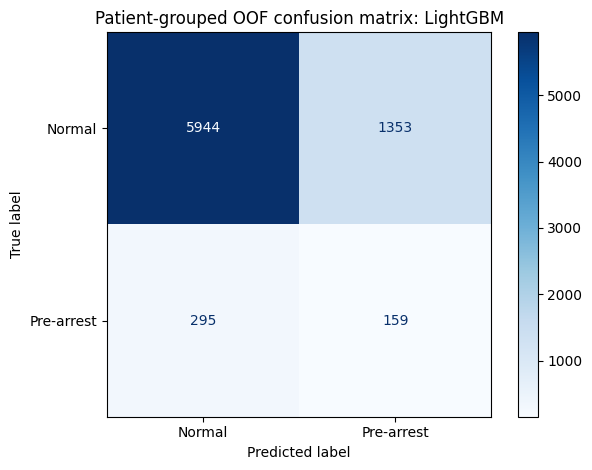

Threshold 0.5 is illustrative, not calibrated for early warnings. Tune thresholds only on training folds.


In [13]:
# MODEL EVALUATION & BEST-MODEL SELECTION (patient-grouped OOF)
# Run immediately after the model comparison cell (cv_df / oof_store).
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score,
                             average_precision_score, classification_report,
                             ConfusionMatrixDisplay)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Keep accuracy visible, but use ROC-AUC and PR-AUC for selection.
# Accuracy is especially misleading with only ~6% positive windows.
metrics_rows = []
for name in cv_df["Model"]:
    repeat_rows = []
    for prob in oof_store[name]:
        pred = (prob >= 0.5).astype(int)
        repeat_rows.append({
            "Accuracy": accuracy_score(y, pred),
            "Balanced Accuracy": balanced_accuracy_score(y, pred),
            "ROC-AUC": roc_auc_score(y, prob),
            "PR-AUC": average_precision_score(y, prob),
            "Precision": precision_score(y, pred, zero_division=0),
            "Recall": recall_score(y, pred, zero_division=0),
            "F1": f1_score(y, pred, zero_division=0)
        })
    metrics_rows.append({"Model": name, **pd.DataFrame(repeat_rows).mean().to_dict()})

results_df = pd.DataFrame(metrics_rows)
prevalence = float(np.mean(y))
# Chance-corrected score: chance-level ROC and PR both contribute zero.
results_df["Selection Score"] = (
    0.5 * (2 * results_df["ROC-AUC"] - 1)
    + 0.5 * (results_df["PR-AUC"] - prevalence) / (1 - prevalence)
)
results_df = results_df.sort_values(["Selection Score", "ROC-AUC"], ascending=False).reset_index(drop=True)
best_name = results_df.loc[0, "Model"]
best_clf = models[best_name]
print("Majority-class accuracy baseline:", f"{max(prevalence, 1-prevalence):.2%}")
print("PR-AUC random baseline:", f"{prevalence:.3f}")
display(results_df.round(4))
print("Selected model:", best_name)
print("LODO evaluation (source shift):")
display(lodo_store[best_name].round(3))

# Show representative repeat rather than averaging probabilities across repeats.
p = oof_store[best_name][0]
pred = (p >= 0.5).astype(int)
print(classification_report(y, pred, labels=[0,1], target_names=["Normal", "Pre-arrest"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y, pred, labels=[0,1], display_labels=["Normal", "Pre-arrest"], cmap="Blues")
plt.title(f"Patient-grouped OOF confusion matrix: {best_name}")
plt.tight_layout(); plt.show()
results_df.to_csv("model_accuracy_auc_results.csv", index=False)
if float(lodo_store[best_name]["ROC-AUC"].mean()) < 0.60:
    print("WARNING: weak transfer to unseen databases; not suitable for clinical deployment.")
print("Threshold 0.5 is illustrative, not calibrated for early warnings. Tune thresholds only on training folds.")

### Interpretation and validation safeguards

- Majority-class accuracy is **94.14%**, so high accuracy by itself is misleading.
- Compare PR-AUC with the positive prevalence (about **5.86%**), and report sensitivity and false alarms per patient-hour.
- Do **not** use the same out-of-fold predictions to tune thresholds and then report their performance as independent test results.
- Verify that `orig_row` is chronological within each patient, that `patient_id` uniquely identifies patients across sources, and that pre-arrest labels come from verified arrest timestamps.
- Model selection on the CV table is exploratory; use a held-out test and external validation before claiming improvement.

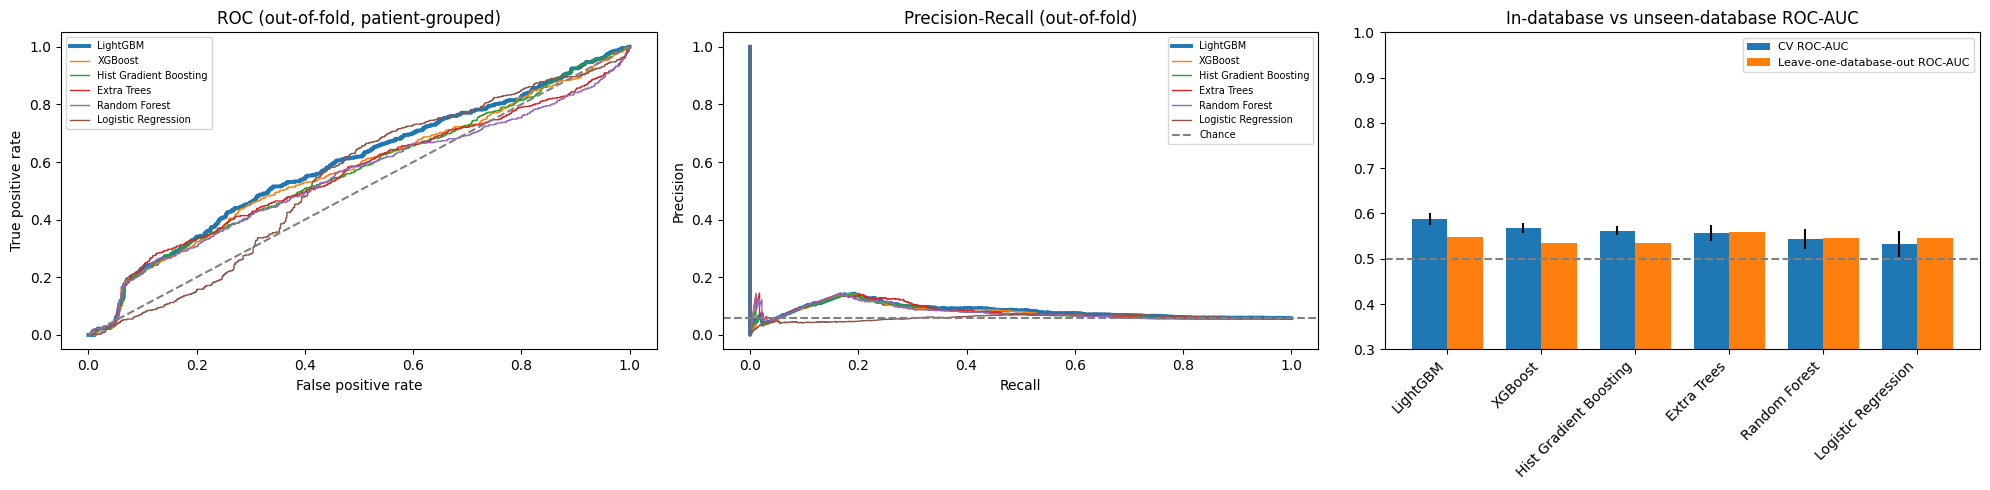

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
for name in cv_df["Model"]:
    p = oof_store[name].mean(0)
    fpr, tpr, _ = roc_curve(y, p); pr_, rc_, _ = precision_recall_curve(y, p)
    lw = 2.8 if name == best_name else 1
    ax[0].plot(fpr, tpr, lw=lw, label=name); ax[1].plot(rc_, pr_, lw=lw, label=name)
ax[0].plot([0, 1], [0, 1], "--", c="grey"); ax[0].set_title("ROC (out-of-fold, patient-grouped)")
ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("True positive rate"); ax[0].legend(fontsize=7)
ax[1].axhline(base_rate, ls="--", c="grey", label="Chance"); ax[1].set_title("Precision-Recall (out-of-fold)")
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].legend(fontsize=7)

xx = np.arange(len(cv_df)); w = 0.38
ax[2].bar(xx - w / 2, cv_df["CV ROC-AUC"], w, yerr=cv_df["ROC std"], label="CV ROC-AUC")
ax[2].bar(xx + w / 2, cv_df["LODO mean ROC-AUC"], w, label="Leave-one-database-out ROC-AUC")
ax[2].axhline(0.5, ls="--", c="grey"); ax[2].set_ylim(0.3, 1.0)
ax[2].set_xticks(xx); ax[2].set_xticklabels(cv_df["Model"], rotation=45, ha="right")
ax[2].set_title("In-database vs unseen-database ROC-AUC"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.savefig("model_comparison.png", dpi=150); plt.show()

## Overfitting & leakage checks
1. **Train vs CV** for the best model: a big gap means memorisation.
2. **Per-database out-of-fold results**: good everywhere, or only where the base rate is high?
3. **Patient-level bootstrap CI**: how much of the score is luck, given so few patients?
4. **Shuffled labels**: must fall to chance.

In [15]:
best_clf = models[best_name]
p_best = oof_store[best_name].mean(0)

# 1. train vs CV
fit_all = make_pipe(best_clf).fit(X, y)
p_tr = fit_all.predict_proba(X)[:, 1]
tr_roc, tr_pr = roc_auc_score(y, p_tr), average_precision_score(y, p_tr)
print(f"1. Train vs CV ({best_name})")
print(f"   ROC-AUC  train {tr_roc:.3f} | CV {b['CV ROC-AUC']:.3f}")
print(f"   PR-AUC   train {tr_pr:.3f} | CV {b['CV PR-AUC']:.3f}")
print("   " + ("WARNING: large train/CV gap -> still memorising; reduce max_depth / raise min_samples_leaf."
                if tr_roc - b["CV ROC-AUC"] > 0.2 else "Gap is moderate."))

# 2. per-database out-of-fold
print("\n2. Per-database out-of-fold performance (compare PR-AUC with that database's base rate)")
rows = []
for s in np.unique(sources):
    m = sources == s; yt = y.values[m]
    if 0 < yt.sum() < len(yt):
        pr = average_precision_score(yt, p_best[m])
        rows.append({"Source": s, "Windows": int(m.sum()), "Patients": len(set(groups[m])), "Positives": int(yt.sum()),
                     "Base rate": yt.mean(), "ROC-AUC": roc_auc_score(yt, p_best[m]), "PR-AUC": pr, "Lift": pr / yt.mean()})
display(pd.DataFrame(rows).set_index("Source").round(3))

# 3. patient-level bootstrap (resample PATIENTS, not windows)
rng = np.random.default_rng(RANDOM_SEED)
pidx = {g: np.where(groups == g)[0] for g in np.unique(groups)}
pats = np.array(list(pidx))
rocs, prs = [], []
for _ in range(300):
    idx = np.concatenate([pidx[g] for g in rng.choice(pats, len(pats), replace=True)])
    yy = y.values[idx]
    if yy.min() == yy.max():
        continue
    rocs.append(roc_auc_score(yy, p_best[idx])); prs.append(average_precision_score(yy, p_best[idx]))
lo, hi = np.percentile(rocs, [2.5, 97.5]); plo, phi = np.percentile(prs, [2.5, 97.5])
print(f"\n3. Patient-level bootstrap 95% CI:  ROC-AUC {np.mean(rocs):.3f} [{lo:.3f}, {hi:.3f}]   PR-AUC {np.mean(prs):.3f} [{plo:.3f}, {phi:.3f}]")
print("   " + ("CI includes 0.5 -> not distinguishable from chance." if lo <= 0.5 else "CI excludes 0.5."))

# 4. shuffled labels
y_shuf = pd.Series(np.random.default_rng(RANDOM_SEED).permutation(y.values), index=y.index)
sh = summarize_oof(oof_predict(best_clf, X, y_shuf, groups, 1), y_shuf)
print(f"\n4. Shuffled-label ROC-AUC {sh['roc']:.3f} (must be ~0.5) | PR-AUC {sh['pr']:.3f} (must be ~{base_rate:.3f})")
print("   " + ("WARNING: above chance with random labels -> leakage/bug." if sh["roc"] > 0.56 else "OK: pipeline is not leaking labels."))

1. Train vs CV (LightGBM)
   ROC-AUC  train 0.937 | CV 0.588
   PR-AUC   train 0.470 | CV 0.086

2. Per-database out-of-fold performance (compare PR-AUC with that database's base rate)


,Windows,Patients,Positives,Base rate,ROC-AUC,PR-AUC,Lift
Source,,,,,,,
mitdb,2932,70,110,0.038,0.626,0.063,1.690
sddb,4286,14,137,0.032,0.451,0.028,0.871
vfdb,533,21,207,0.388,0.477,0.357,0.920



3. Patient-level bootstrap 95% CI:  ROC-AUC 0.592 [0.516, 0.659]   PR-AUC 0.086 [0.055, 0.125]
   CI excludes 0.5.

4. Shuffled-label ROC-AUC 0.510 (must be ~0.5) | PR-AUC 0.063 (must be ~0.059)
   OK: pipeline is not leaking labels.


## Pre-arrest risk state
Probabilities are smoothed per patient (causal rolling median), then turned into states with an **alert budget**:
WATCH = top `WATCH_RATE` of windows, WARNING = top `WARNING_RATE`. Thresholds come from out-of-fold predictions only.

In [16]:
order = df[ORDER_COL].values
p_raw = oof_store[best_name].mean(0)
p_s = smooth_by_patient(p_raw, groups, order, SMOOTH_K)
print(f"Out-of-fold ROC-AUC: raw {roc_auc_score(y, p_raw):.3f} -> smoothed (k={SMOOTH_K}) {roc_auc_score(y, p_s):.3f}")
print(f"Out-of-fold PR-AUC : raw {average_precision_score(y, p_raw):.3f} -> smoothed {average_precision_score(y, p_s):.3f}")

T_WATCH = float(np.quantile(p_s, 1 - WATCH_RATE))
T_WARNING = max(float(np.quantile(p_s, 1 - WARNING_RATE)), T_WATCH)
state = risk_state(p_s, T_WATCH, T_WARNING)
print(f"\nWATCH threshold   (top {WATCH_RATE:.0%}): {T_WATCH:.3f}\nWARNING threshold (top {WARNING_RATE:.0%}): {T_WARNING:.3f}")

print("\nState vs actual (out-of-fold, all patients):")
display(pd.crosstab(pd.Series(state, name="Predicted state"), y.rename("Actual"), margins=True))

flag = state != "STABLE"
recall = flag[y.values == 1].mean(); fa = flag[y.values == 0].mean(); prec = y.values[flag].mean()
print(f"Pre-arrest windows flagged (recall)     : {recall:.1%}")
print(f"Normal windows flagged (false-alarm)    : {fa:.1%}")
print(f"Precision of flagged windows            : {prec:.1%}  (chance {base_rate:.1%}, lift {prec / base_rate:.2f}x)")

dd = pd.DataFrame({"g": groups, "src": sources, "y": y.values, "flag": flag})
det = dd[dd.y == 1].groupby("g").agg(src=("src", "first"), flagged_frac=("flag", "mean"))
print(f"Patient-level: {(det.flagged_frac > 0).mean():.0%} of patients with a pre-arrest window got at least one alert inside it "
      f"(median share of their pre-arrest windows flagged: {det.flagged_frac.median():.0%})")
display(dd.groupby("src").apply(lambda t: pd.Series({
    "recall": t.flag[t.y == 1].mean() if (t.y == 1).any() else np.nan,
    "false_alarm_rate": t.flag[t.y == 0].mean(), "alert_rate": t.flag.mean()})).round(3))

Out-of-fold ROC-AUC: raw 0.592 -> smoothed (k=5) 0.599
Out-of-fold PR-AUC : raw 0.083 -> smoothed 0.083

WATCH threshold   (top 5%): 0.735
WARNING threshold (top 1%): 0.748

State vs actual (out-of-fold, all patients):


Actual,0,1,All
Predicted state,,,
PRE-ARREST WARNING,81,0,81
STABLE,6920,441,7361
WATCH,296,13,309
All,7297,454,7751


Pre-arrest windows flagged (recall)     : 2.9%
Normal windows flagged (false-alarm)    : 5.2%
Precision of flagged windows            : 3.3%  (chance 5.9%, lift 0.57x)
Patient-level: 9% of patients with a pre-arrest window got at least one alert inside it (median share of their pre-arrest windows flagged: 0%)


,recall,false_alarm_rate,alert_rate
src,,,
mitdb,0.027,0.097,0.095
sddb,0.000,0.008,0.008
vfdb,0.048,0.206,0.144


,Field,Importance (ROC-AUC drop),Std
0,premature_fraction_zstd,0.0500,0.0027
1,mean_rr_zstd,0.0270,0.0034
2,cv_rr_zmean,0.0223,0.0008
3,premature_fraction_z,0.0151,0.0009
4,min_rr_zmean,0.0137,0.0007
5,mean_rr_zmean,0.0134,0.0012
6,pnn50_zstd,0.0134,0.0006
7,sd2_zmean,0.0126,0.0013
8,premature_fraction_zmean,0.0119,0.0002
9,pnn50_zmean,0.0092,0.0007


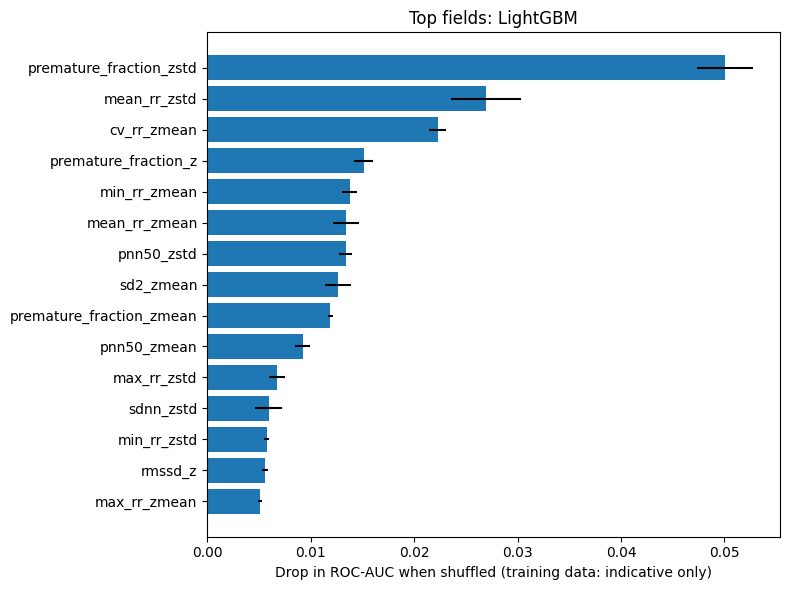

In [17]:
# ---- Feature importance (permutation on the final model; computed on training data, so indicative only) ----
from sklearn.inspection import permutation_importance
perm = permutation_importance(fit_all, X, y, scoring="roc_auc", n_repeats=3, random_state=RANDOM_SEED, n_jobs=-1)
imp = (pd.DataFrame({"Field": X.columns, "Importance (ROC-AUC drop)": perm.importances_mean, "Std": perm.importances_std})
         .sort_values("Importance (ROC-AUC drop)", ascending=False).reset_index(drop=True))
display(imp.head(15).round(4))
top = imp.head(15).iloc[::-1]
plt.figure(figsize=(8, 6)); plt.barh(top["Field"], top["Importance (ROC-AUC drop)"], xerr=top["Std"])
plt.xlabel("Drop in ROC-AUC when shuffled (training data: indicative only)"); plt.title(f"Top fields: {best_name}")
plt.tight_layout(); plt.savefig("top_predictive_fields.png", dpi=150); plt.show()
imp.to_csv("field_importance.csv", index=False)

In [18]:
# ---- Save the final model (trained on ALL patients) + inference helper ----
assert not NORMALIZE_PER_SOURCE, "NORMALIZE_PER_SOURCE=True cannot be deployed on a patient from an unknown database."
config = dict(base_feats=BASE_FEATS, group_col=GROUP_COL, order_col=ORDER_COL, feature_set=FEATURE_SET,
              baseline_mode=BASELINE_MODE, min_history=MIN_HISTORY, short_win=SHORT_WIN, smooth_k=SMOOTH_K)
bundle = dict(pipeline=fit_all, feature_columns=list(X.columns), config=config, model=best_name,
              t_watch=T_WATCH, t_warning=T_WARNING,
              cv=dict(roc=float(b["CV ROC-AUC"]), pr=float(b["CV PR-AUC"]), lodo_roc=float(b["LODO mean ROC-AUC"])))
joblib.dump(bundle, "pre_arrest_predictor.joblib")

def predict_pre_arrest(new_df, bundle_path=None):
    """new_df: raw windows with the patient_id, orig_row (time order) and BASE_FEATS columns.
    Needs a patient's earlier windows to build the baseline (the first MIN_HISTORY windows get neutral features)."""
    bd = bundle if bundle_path is None else joblib.load(bundle_path)
    c = bd["config"]
    Xn = build_features(new_df, c["base_feats"], c["group_col"], c["order_col"], c["feature_set"],
                        c["baseline_mode"], c["min_history"], c["short_win"])
    p = bd["pipeline"].predict_proba(Xn[bd["feature_columns"]])[:, 1]
    ps = smooth_by_patient(p, new_df[c["group_col"]].values, new_df[c["order_col"]].values, c["smooth_k"])
    out = new_df.copy()
    out["risk_probability"] = np.round(ps, 4)
    out["pre_arrest_state"] = risk_state(ps, bd["t_watch"], bd["t_warning"])
    return out

demo = predict_pre_arrest(df[df[GROUP_COL].isin(df[GROUP_COL].unique()[:3])])
display(demo[[GROUP_COL, ORDER_COL, TARGET_COL, "risk_probability", "pre_arrest_state"]].tail(8))
print("Saved: pre_arrest_predictor.joblib, pre_arrest_features.py, cv_results.csv, field_importance.csv, model_comparison.png")

try:
    from google.colab import files
    for f in ["pre_arrest_predictor.joblib", "pre_arrest_features.py", "cv_results.csv", "model_comparison.png"]:
        files.download(f)
except ImportError:
    pass

,patient_id,orig_row,label_prearrest,risk_probability,pre_arrest_state
169,mitdb_102,702,0,0.0713,STABLE
170,mitdb_102,703,0,0.0676,STABLE
171,mitdb_102,704,0,0.0595,STABLE
172,mitdb_102,705,0,0.0483,STABLE
173,mitdb_102,706,0,0.0438,STABLE
174,mitdb_102,707,0,0.0437,STABLE
175,mitdb_102,708,0,0.0437,STABLE
176,mitdb_102,709,0,0.0437,STABLE


Saved: pre_arrest_predictor.joblib, pre_arrest_features.py, cv_results.csv, field_importance.csv, model_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to read the results
* **LODO ROC-AUC is the number that matters.** CV on windows from databases the model has already seen can be inflated by database-specific quirks; an unseen database cannot.
* **ROC-AUC 0.5 = coin flip.** If the verdict says "does not generalise", tuning models will not help. Look at the ablation table, the data diagnostics (are there patients with their own normal windows?), then add patients or features.
* Use `FEATURE_SET`, `SOURCES_TO_USE` and `NORMALIZE_PER_SOURCE` in the Config cell to run the experiments, and compare the LODO columns each time.
* Every number here comes from patient-grouped validation. No patient appears in both the training and validation side of any fold.